In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
anime_df = pd.read_csv('anime.csv')

In [3]:
anime_df.head()

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266


In [4]:
print('Dataset Shape:', anime_df.shape)
print(anime_df.head())
print(anime_df.info())

Dataset Shape: (12294, 7)
   anime_id                              name  \
0     32281                    Kimi no Na wa.   
1      5114  Fullmetal Alchemist: Brotherhood   
2     28977                          Gintama°   
3      9253                       Steins;Gate   
4      9969                     Gintama&#039;   

                                               genre   type episodes  rating  \
0               Drama, Romance, School, Supernatural  Movie        1    9.37   
1  Action, Adventure, Drama, Fantasy, Magic, Mili...     TV       64    9.26   
2  Action, Comedy, Historical, Parody, Samurai, S...     TV       51    9.25   
3                                   Sci-Fi, Thriller     TV       24    9.17   
4  Action, Comedy, Historical, Parody, Samurai, S...     TV       51    9.16   

   members  
0   200630  
1   793665  
2   114262  
3   673572  
4   151266  
<class 'pandas.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null

In [5]:
anime_df['genre'].fillna('', inplace=True)
anime_df['type'].fillna('', inplace=True)
anime_df['name'].fillna('Unknown', inplace=True)

/var/folders/70/s6bttn7d6_qdr8b28nj_vt640000gn/T/ipykernel_80453/1570980655.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  anime_df['genre'].fillna('', inplace=True)
/var/folders/70/s6bttn7d6_qdr8b28nj_vt640000gn/T/ipykernel_80453/1570980655.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series th

0                                           Kimi no Na wa.
1                         Fullmetal Alchemist: Brotherhood
2                                                 Gintama°
3                                              Steins;Gate
4                                            Gintama&#039;
                               ...                        
12289         Toushindai My Lover: Minami tai Mecha-Minami
12290                                          Under World
12291                       Violence Gekiga David no Hoshi
12292    Violence Gekiga Shin David no Hoshi: Inma Dens...
12293                     Yasuji no Pornorama: Yacchimae!!
Name: name, Length: 12294, dtype: str

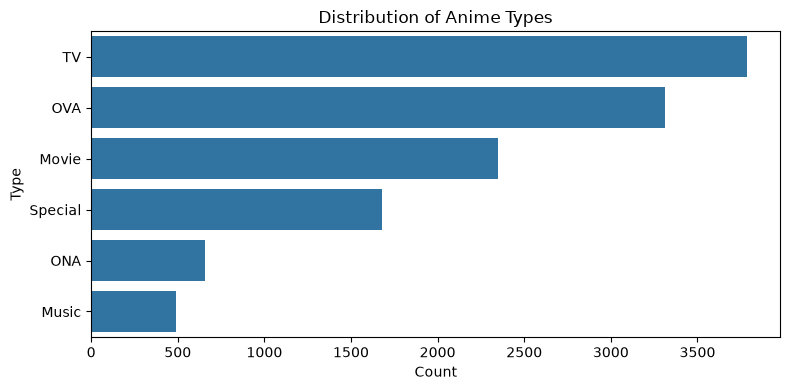

In [6]:
plt.figure(figsize=(8, 4))
sns.countplot(
    y='type', data=anime_df, order=anime_df['type'].value_counts().index
)
plt.title('Distribution of Anime Types')
plt.xlabel('Count')
plt.ylabel('Type')
plt.tight_layout()
plt.show()

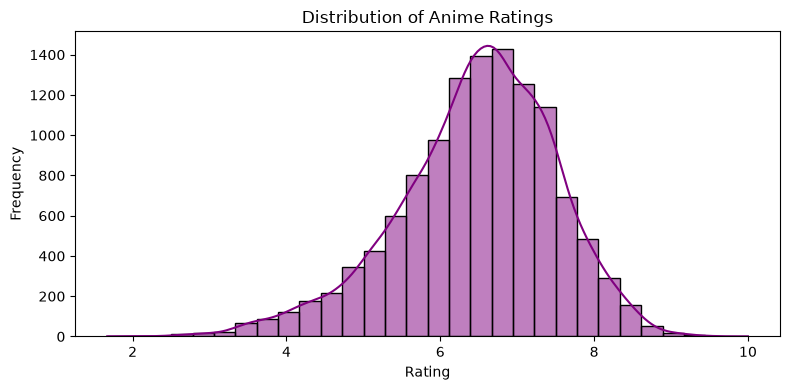

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(anime_df['rating'].dropna(), bins=30, kde=True, color='purple')
plt.title('Distribution of Anime Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [11]:
anime_df['genre'] = anime_df['genre'].fillna('').astype(str)
anime_df['type'] = anime_df['type'].fillna('').astype(str)
anime_df['name'] = anime_df['name'].fillna('').astype(str)


In [12]:
anime_df['features'] = (
    anime_df['genre'] + ' ' + anime_df['type'] + ' ' + anime_df['name']
)

In [13]:
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(anime_df['features'])

print('TF-IDF Matrix Shape:', tfidf_matrix.shape)

TF-IDF Matrix Shape: (12294, 12002)


In [14]:
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

In [18]:
def get_recommendations(title, cosine_sim=cosine_sim):

  indices = pd.Series(anime_df.index, index=anime_df['name']).drop_duplicates()

  if title not in indices:
    return [f"'{title}' not found in the database."]

  
  idx = indices[title]

  
  sim_scores = list(enumerate(cosine_sim[idx]))

  
  sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

  
  sim_scores = sim_scores[1:11]

  
  anime_indices = [i[0] for i in sim_scores]

 
  return anime_df['name'].iloc[anime_indices].tolist()

In [19]:
test_anime = 'Kimi no Na wa.'
recommendations = get_recommendations(test_anime)

print(f'\nTop 10 Recommendations for "{test_anime}":')
for i, rec in enumerate(recommendations, 1):
  print(f'{i}. {rec}')


Top 10 Recommendations for "Kimi no Na wa.":
1. Kimi to Boku. 2
2. Kimi to Boku.
3. Kimi no Na wo Yobeba
4. Shigatsu wa Kimi no Uso
5. Myself; Yourself
6. Kimi wa Tomodachi
7. Bleach Movie 3: Fade to Black - Kimi no Na wo Yobu
8. Nozo x Kimi
9. Jitsu wa Watashi wa
10. Kimi to Boku


In [20]:
import joblib

joblib.dump(cosine_sim, 'cosine_sim.pkl')
joblib.dump(anime_df, 'anime_df.pkl')

['anime_df.pkl']